# E1 Random Forest

Can these fixed acoustic features classify unseen speakers from the two corpora?

This run uses the existing 2,000 audio clips. Label 1 is MNSC / Singapore.
Label 0 is Common Voice / non-Singapore. Corpus and class are linked.
High scores do not establish accent recognition under new recording conditions.

All six matched notebooks use one saved clip list and one speaker split.
Training and validation select settings. Test speakers measure the fixed model.
The first grouped fold supplies test data. This is **one split**, not full cross-validation.

Shared implementation: [experiment_common.py](experiment_common.py).
Read its audio and evaluation functions to inspect the full procedure.
The original notebooks were backed up before this update.

## 1. Use the local audio environment

Use the **Singlish audio review (Python 3.12)** kernel.
Dependencies are already installed. This notebook does not upgrade packages.
Set the two paths below if the project moves.

In [1]:
from pathlib import Path
import sys

USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'audio'
else:
    PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'e1_audio_1000x2' / 'data'

sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

%matplotlib inline
config = common.configure(PROJECT_ROOT, DATA_ROOT)
print('Audio:', DATA_ROOT)
print('Results:', config['output'])
print(json.dumps(common.environment(), indent=2))

Audio: /home/mh/nusproj/singlish-whisper/data/e1_audio_1000x2/data
Results: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42
{
  "python": "3.12.13",
  "packages": {
    "numpy": "2.5.1",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.0",
    "librosa": "1.0.0",
    "torch": "2.13.0+cu126",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 2. Verify clips and load the shared split

File hashes detect duplicate audio. Extraction failures stop the run.
No notebook silently drops clips or creates a different test set.
Each speaker stays in one partition. The split is approximately 64% / 16% / 20%.
The saved split remains fixed on later runs.

In [2]:
frame, fingerprint = common.prepare_manifest(config)
split = common.shared_split(config, frame, fingerprint)
y = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
train_idx, val_idx, test_idx = (split[name] for name in ['train', 'validation', 'test'])
trainval_idx = np.sort(np.r_[train_idx, val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb
{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.


## 3. Load the shared 39 acoustic features

Each clip is mono and sampled at 16 kHz. We trim outer silence and normalize its peak.
We keep at most six seconds. Clips shorter than one second receive zero padding.
The 39 columns contain 26 MFCC statistics, three pitch statistics, and ten other statistics.
Pitch uses an energy gate. This gate is not a validated voicing detector.
These features are predefined. This run does not prove they are the best feature subset.

In [3]:
X = common.load_features(config, frame, fingerprint, whisper=False)
print(list(zip(range(39), common.FEATURE_NAMES)))

Acoustic features: (2000, 39)
[(0, 'mfcc_1_mean'), (1, 'mfcc_2_mean'), (2, 'mfcc_3_mean'), (3, 'mfcc_4_mean'), (4, 'mfcc_5_mean'), (5, 'mfcc_6_mean'), (6, 'mfcc_7_mean'), (7, 'mfcc_8_mean'), (8, 'mfcc_9_mean'), (9, 'mfcc_10_mean'), (10, 'mfcc_11_mean'), (11, 'mfcc_12_mean'), (12, 'mfcc_13_mean'), (13, 'mfcc_1_std'), (14, 'mfcc_2_std'), (15, 'mfcc_3_std'), (16, 'mfcc_4_std'), (17, 'mfcc_5_std'), (18, 'mfcc_6_std'), (19, 'mfcc_7_std'), (20, 'mfcc_8_std'), (21, 'mfcc_9_std'), (22, 'mfcc_10_std'), (23, 'mfcc_11_std'), (24, 'mfcc_12_std'), (25, 'mfcc_13_std'), (26, 'pitch_mean'), (27, 'pitch_std'), (28, 'energy_gated_pitch_fraction'), (29, 'centroid_mean'), (30, 'centroid_std'), (31, 'bandwidth_mean'), (32, 'bandwidth_std'), (33, 'rolloff_mean'), (34, 'rolloff_std'), (35, 'zcr_mean'), (36, 'zcr_std'), (37, 'rms_mean'), (38, 'rms_std')]


## 4. Select settings on validation speakers

Every candidate uses training speakers only. Validation macro F1 selects the model.
Balanced accuracy breaks ties. Candidate order breaks any remaining tie.
The candidate grid is fixed before test evaluation.

In [4]:
from sklearn.ensemble import RandomForestClassifier

# Trees do not need feature scaling. OOB is disabled: it is not a speaker-held-out test.
candidates = [
    (f'leaf={leaf}, max_features={features}', RandomForestClassifier(
        n_estimators=300, min_samples_leaf=leaf, max_features=features,
        class_weight='balanced', n_jobs=4, random_state=common.SEED, oob_score=False))
    for leaf in [1, 2, 4] for features in ['sqrt', 0.5]
]

In [5]:
selected_model, validation = common.choose_candidate(candidates, X, y, split)
common.write_json(config['output'] / 'e1_random_forest' / 'validation_selection.json', validation)

                candidate  macro_f1  balanced_accuracy
leaf=1, max_features=sqrt  0.928124           0.928125
 leaf=1, max_features=0.5  0.931247           0.931250
leaf=2, max_features=sqrt  0.918747           0.918750
 leaf=2, max_features=0.5  0.924997           0.925000
leaf=4, max_features=sqrt  0.921868           0.921875
 leaf=4, max_features=0.5  0.918737           0.918750
Validation choice: leaf=1, max_features=0.5


Forest scores are not assumed to be calibrated probabilities.
The extra plot uses validation permutation importance. It does not use test labels.
Correlated features can share importance. Importance does not establish causation.

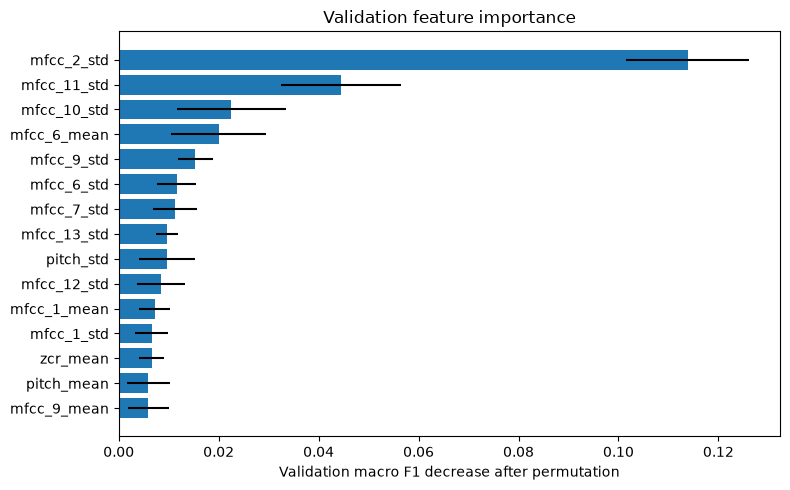

In [6]:
from sklearn.inspection import permutation_importance

# Use the train-fitted model and validation data, before the final refit.
importance = permutation_importance(selected_model, X[val_idx], y[val_idx],
    scoring='f1_macro', n_repeats=10, random_state=common.SEED, n_jobs=4)
order = np.argsort(importance.importances_mean)[-15:]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(common.FEATURE_NAMES)[order], importance.importances_mean[order],
        xerr=importance.importances_std[order])
ax.set(xlabel='Validation macro F1 decrease after permutation', title='Validation feature importance')
fig.tight_layout()
fig.savefig(config['output'] / 'e1_random_forest' / 'validation_feature_importance.png', dpi=160)
plt.show()
plt.close(fig)
pd.DataFrame({'feature': common.FEATURE_NAMES, 'mean_decrease': importance.importances_mean,
              'std_decrease': importance.importances_std}).to_csv(
    config['output'] / 'e1_random_forest' / 'validation_feature_importance.csv', index=False)

## 5. Refit the selected model, then evaluate test speakers

Settings are now fixed. Refit the model on training plus validation speakers.
All learned preprocessing is refitted on those speakers only.
Report macro F1, balanced accuracy, ROC AUC, class metrics, and error counts.
Confidence intervals resample whole speakers within each class.
They describe this fitted model and split. They do not measure variation across training splits.

{
  "accuracy": 0.92,
  "macro_f1": 0.9199819959490885,
  "balanced_accuracy": 0.92,
  "roc_auc": 0.9729875,
  "errors": 32,
  "confusion_matrix": [
    [
      181,
      19
    ],
    [
      13,
      187
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.06312658333333333,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.8836617292681649,
      0.9522577996715927
    ],
    "balanced_accuracy": [
      0.8836984833336965,
      0.9523448843675449
    ],
    "macro_f1": [
      0.8834135704102397,
      0.9522572028754355
    ]
  }
}


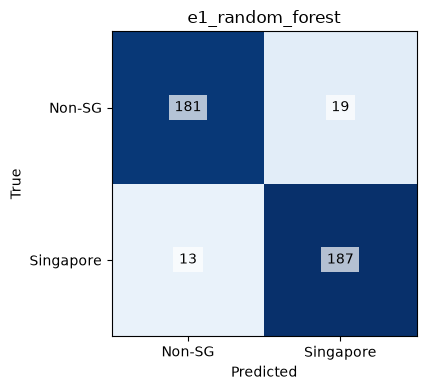

,clip_id,path,group,label,prediction,score_class_1,error
0,non_singapore/speaker_073/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_073,0,1,0.616667,True
1,non_singapore/speaker_092/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_092,0,1,0.743333,True
2,non_singapore/speaker_093/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_093,0,1,0.603333,True
3,non_singapore/speaker_093/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_093,0,1,0.543333,True
4,non_singapore/speaker_098/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_098,0,1,0.690000,True
5,non_singapore/speaker_132/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_132,0,1,0.636667,True
6,non_singapore/speaker_132/clip_003.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_132,0,1,0.530000,True
7,non_singapore/speaker_162/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_162,0,1,0.530000,True
8,non_singapore/speaker_165/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_165,0,1,0.523333,True
9,non_singapore/speaker_225/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_225,0,1,0.953333,True


In [7]:
model = clone(selected_model).fit(X[trainval_idx], y[trainval_idx])
predicted = model.predict(X[test_idx])
scores, is_probability = common.predict_scores(model, X[test_idx])
report = common.save_result(config, 'e1_random_forest', frame, fingerprint, split, model,
    predicted, scores, validation, probability=is_probability,
    extra={'features': 39, 'decision_rule': 'model.predict', 'training': 'refit on train plus validation'})
display(pd.read_csv(config['output'] / 'e1_random_forest' / 'test_errors.csv'))

## 6. Predict one recording with the same decision rule

This helper applies the same waveform preparation and feature extraction.
The model output is a dataset class prediction. It does not identify a person's background.

In [8]:
def predict_recording(audio_path):
    waveform, _ = common.prepare_audio(Path(audio_path))
    features = common.acoustic_features(waveform).reshape(1, -1)
    predicted = int(model.predict(features)[0])
    score, is_probability = common.predict_scores(model, features)
    return {'predicted_label': predicted, 'score_class_1': float(score[0]),
            'score_type': 'model probability' if is_probability else 'SVM decision score'}

print(predict_recording(frame.path.iloc[test_idx[0]]))

/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'predicted_label': 0, 'score_class_1': 0.016666666666666666, 'score_type': 'model probability'}


## Interpretation

Compare this result with other models on the same saved split.
Do not tune again after inspecting test errors. Record later changes as a new experiment.
A high score can reflect corpus or microphone differences. A matched-source test remains necessary.

## Recorded result: 28 October 2026

Accuracy: **92.00%**. Macro F1: **0.9200**.
There were **32 errors among 400 test clips** from 176 speakers.
Non-Singapore clips predicted as Singapore: **19**.
Singapore clips predicted as non-Singapore: **13**.
The 95% speaker-bootstrap interval for macro F1 is **[0.8834, 0.9523]**.

Validation selected **leaf=1, max_features=0.5**.

Class and corpus remain linked. These scores do not isolate accent from recording-source effects.
Artifacts: `../outputs/matched_2000_seed42/e1_random_forest/`.